### Current baseline assumptions

Each innocent player starts with equal probability that any other player is Mafia. Private investigation results use a symmetric noise model: the result is correct with probability `reliability`, which the detective knows.

For a public accusation, `receive_accusation()` tests each possible Mafia identity and assigns a likelihood to the observed message:

- If the speaker is Mafia: `1/3`, assuming a random accusation against one of the other three players.
- If the speaker is innocent and accuses Mafia: `prob_innocent_finds_mafia`, currently `0.5`.
- If the speaker is innocent and accuses another innocent: `(1 - prob_innocent_finds_mafia) / 2`, currently `0.25` for each of the two innocent alternatives.

The agent multiplies each prior by its likelihood and normalizes. Repeated identical accusations from the same speaker are ignored. New accusations are processed as additional evidence without explicitly modeling their dependence on earlier discussion; message confidence is not used.

These are assumptions used by the observer, not measured detection rates. Actual innocent players accuse a highest-belief target, while Mafia targets an innocent with the most previous accusations, so the likelihood model does not exactly match the speaking policies. This is an approximate Bayesian baseline, not an optimal agent.

Equal-probability targets are chosen randomly. Final voting ties still count as Mafia wins.

### Discussion rounds

Set `discussion_rounds` in the simulation cell to `1`, `2`, or `3`. Each game has one investigation, the selected number of discussion rounds, and one final vote. Every player speaks once per round, with speaking order shuffled again each round. Beliefs and accusation history carry over between rounds. Repeated identical accusations from the same speaker still do not add evidence. The default remains one round for comparison with the previous notebook.

In [16]:
import random

#Assumed innocent accusation accuracy, not a measured rate
prob_innocent_finds_mafia = 0.5

class Villager:
  def __init__(self, id, players):
    self.id = id
    self.players = players

    self.possible_mafia = [p for p in players if p!=self.id]
    self.beliefs = [1 / len(self.possible_mafia) for p in players]
    self.beliefs[id] = 0

    self.history = []

  def receive_detective(self, target, result, reliability):
    self.target = target
    self.result = result
    self.reliability = reliability
    self.update_beliefs(target, result, reliability)

  def update_beliefs(self, target, result, reliability):
    for mafia in self.possible_mafia:
      if mafia==target:
        if result==1: #Is Mafia
          likelihood = reliability
        else:
          likelihood = 1 - reliability
      else:
        if result==1: #Is Mafia
          likelihood = 1 - reliability
        else:
          likelihood = reliability
      self.beliefs[mafia] = self.beliefs[mafia] * likelihood

    total = 0.0
    for b in self.beliefs:
      total += b
    self.beliefs = [b / total for b in self.beliefs]

  def vote(self):
    maxp = -1
    max_players = []

    for player in range(len(self.beliefs)):
      if self.beliefs[player] > maxp:
        maxp = self.beliefs[player]
        max_players = [player]
      elif self.beliefs[player] == maxp:
        max_players += [player]
    return random.choice(max_players)

  def generate_message(self):
    target=self.vote()
    return {"accused_player": target, "confidence": self.beliefs[target]}

  def receive_accusation(self, speaker, accused):
    if (speaker, accused) in self.history:
      return
    for mafia in self.possible_mafia:
      if speaker==mafia:
        likelihood = 1/3 #Observer assumes random Mafia accusations
      elif accused==mafia:
        likelihood = prob_innocent_finds_mafia
      else:
        likelihood = (1 - prob_innocent_finds_mafia) / 2
      self.beliefs[mafia] = self.beliefs[mafia] * likelihood
    total = 0.0
    for b in self.beliefs:
      total += b
    self.beliefs = [b / total for b in self.beliefs]
    self.history += [(speaker, accused)]



In [17]:
class Detective(Villager):
  def __init__(self, id, players):
    super().__init__(id, players)
    self.investigations = []
    self.revealed_investigations = []

  def choose_investigation(self):
    uninvestigated = [p for p in self.players if p != self.id and p not in [inv[0] for inv in self.investigations]]
    if len(uninvestigated)==0:
      return None

    maxp = -1
    max_players = []

    for player in uninvestigated:
      if self.beliefs[player] > maxp:
        maxp = self.beliefs[player]
        max_players = [player]
      elif self.beliefs[player] == maxp:
        max_players += [player]
    return random.choice(max_players)

  def receive_investigation(self, target, result, reliability):
    self.investigations += [(target, result, reliability)]
    self.update_beliefs(target, result, reliability)

  def decide_reveal(self):
    if len(self.investigations) == 0: return None
    (target, result, reliability) = self.investigations[-1]
    if (target, result, reliability) in self.revealed_investigations: return None
    if result == 1: # and reliability >= 0.8:
      self.revealed_investigations += [(target, result, reliability)]
      #return {"claim_detective":True, "investigated_player": target, "result": result, "reliability": reliability}
      return {"accused_player": target, "confidence": reliability}
    else:
      return None

  def generate_message(self):
    temp = self.decide_reveal()
    if temp != None:
      return temp
    else:
      return super().generate_message()

In [18]:
import random
class Mafia():
  def __init__(self, id, players):
    self.id = id
    self.players = players
    self.innocent_players = [p for p in players if p!=self.id]
    self.accusation_history = []
    self.current_target = None

  def receive_accusation(self, speaker, accused):
    if speaker==accused or (speaker, accused) in self.accusation_history:
      return
    self.accusation_history += [(speaker, accused)]

  def choose_target(self):
    accusation_counts = {}
    for p in self.innocent_players:
      accusation_counts[p] = 0
    for (speaker, accused) in self.accusation_history:
      if accused in self.innocent_players:
        accusation_counts[accused] += 1
    max_count = -1
    max_player = []
    for p in self.innocent_players:
      if accusation_counts[p] > max_count:
        max_count = accusation_counts[p]
        max_player = [p]
      elif accusation_counts[p] == max_count:
        max_player += [p]
    if len(max_player) == 1:
      return max_player[0]
    else:
      return random.choice(max_player)

  def generate_message(self):
    self.current_target = self.choose_target()
    return {"accused_player": self.current_target, "confidence": 0.8}

  def vote(self):
    if self.current_target != None:
      return self.current_target
    return self.choose_target()


In [19]:
class Game:
  def __init__(self, reliability, discussion_rounds=1):
    if not isinstance(discussion_rounds, int) or discussion_rounds < 1:
      raise ValueError("discussion_rounds must be a positive integer")
    self.discussion_rounds = discussion_rounds
    self.players = [i for i in range(4)]
    assignments = [i for i in range(4)]
    random.shuffle(assignments)
    self.villagers = [Villager(i, self.players) for i in assignments[:2]]
    self.detective = Detective(assignments[2], self.players)
    self.mafia = Mafia(assignments[3], self.players)
    self.agents = {}
    for agent in self.villagers + [self.detective, self.mafia]:
      self.agents[agent.id] = agent
    self.mafia_id = assignments[3]
    self.detective_id = assignments[2]
    self.public_messages = []
    self.reliability = reliability
    self.votes = {}

  def investigation(self):
    target = self.detective.choose_investigation()
    if target == None:
      return

    actual_result = 0
    if target==self.mafia_id:
      actual_result = 1
    if random.random() < self.reliability:
      observed = actual_result
    else:
      observed = 1 - actual_result

    self.detective.receive_investigation(target, observed, self.reliability)

  def discussion(self):
    order = self.players.copy()
    random.shuffle(order)
    for p in order:
      message = self.agents[p].generate_message()
      self.public_messages += [(p, message)]

      for p1 in self.players:
        if p != p1:
          self.agents[p1].receive_accusation(p, message["accused_player"])
  def vote(self):
    self.votes = {}
    for p in self.players:
      target = self.agents[p].vote()
      self.votes[p] = target

    vote_counts = {}
    for p in self.players:
      vote_counts[p] = 0
    for target in self.votes.values():
      vote_counts[target] += 1
    max_count = max(vote_counts.values())
    max_players = []
    for p in self.players:
      if vote_counts[p] == max_count:
        max_players += [p]
    if len(max_players) > 1: return None
    return max_players[0]

  def winner(self, eliminated_player):
    if eliminated_player == self.mafia_id:
      return "Villager"
    else:
      return "Mafia"

  def play(self):
    self.investigation()
    for round in range(self.discussion_rounds):
      self.discussion()
    eliminated = self.vote()
    winner = self.winner(eliminated)
    return {"winner":winner, "eliminated":eliminated, "votes":self.votes, "public_messages":self.public_messages}




100%|██████████| 21/21 [00:06<00:00,  3.44it/s]

Reliability: 0 , Villager Win Rate: 0.2553
Reliability: 0.05 , Villager Win Rate: 0.2494
Reliability: 0.1 , Villager Win Rate: 0.2253
Reliability: 0.15 , Villager Win Rate: 0.2262
Reliability: 0.2 , Villager Win Rate: 0.2076
Reliability: 0.25 , Villager Win Rate: 0.1965
Reliability: 0.3 , Villager Win Rate: 0.1746
Reliability: 0.35 , Villager Win Rate: 0.212
Reliability: 0.4 , Villager Win Rate: 0.2175
Reliability: 0.45 , Villager Win Rate: 0.2253
Reliability: 0.5 , Villager Win Rate: 0.2291
Reliability: 0.55 , Villager Win Rate: 0.2468
Reliability: 0.6 , Villager Win Rate: 0.2565
Reliability: 0.65 , Villager Win Rate: 0.2683
Reliability: 0.7 , Villager Win Rate: 0.3493
Reliability: 0.75 , Villager Win Rate: 0.3662
Reliability: 0.8 , Villager Win Rate: 0.4059
Reliability: 0.85 , Villager Win Rate: 0.4264
Reliability: 0.9 , Villager Win Rate: 0.4452
Reliability: 0.95 , Villager Win Rate: 0.4787
Reliability: 1.0 , Villager Win Rate: 0.4912


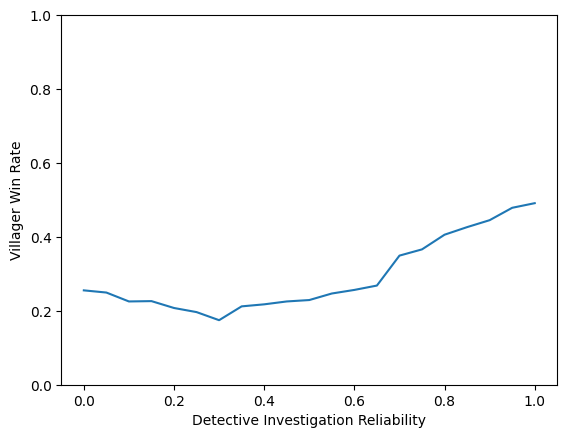

In [20]:
import matplotlib.pyplot as plt
from tqdm import tqdm

results = {}
reliabilities = [0, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 1.0]
num_games = 10000
discussion_rounds = 1 #Change to 2 or 3 for more discussion

for reliability in tqdm(reliabilities):
  villager_wins = 0

  for i in range(num_games):
    game = Game(reliability, discussion_rounds)
    result = game.play()
    if result["winner"] == "Villager":
      villager_wins += 1
  results[reliability] = villager_wins / num_games

for reliability, win_rate in results.items():
  print("Reliability:", reliability, ", Villager Win Rate:", win_rate)

plt.plot(list(results.keys()), list(results.values()))
plt.xlabel("Detective Investigation Reliability")
plt.ylabel("Villager Win Rate")
plt.ylim(0,1)
plt.show()

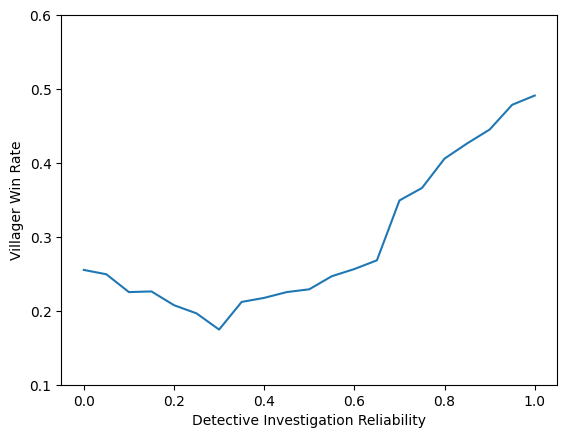

In [21]:
plt.plot(list(results.keys()), list(results.values()))
plt.xlabel("Detective Investigation Reliability")
plt.ylabel("Villager Win Rate")
plt.ylim(0.1,0.6)
plt.show()

### Experiment: comparing discussion rounds

We compare one, two, and three discussion rounds across the same investigation reliabilities. Only the number of discussion rounds changes: agent policies, one private investigation, one final vote, and Mafia winning voting ties stay fixed.

Run the agent and Game definition cells first. This section uses its own settings and `round_comparison_results`, leaving the earlier sweep and its results untouched. With 10,000 games per configuration, the full comparison runs 630,000 games.

Each game uses seed `comparison_seed + comparison_i`, reused across configurations to match initial role assignments, investigation targets, and investigation random draws. Later random choices can diverge as the games progress. The previous random state is restored when the experiment finishes. Re-running these cells with the same settings reproduces the comparison.

Repeated identical accusations are still ignored. The plot is descriptive; small differences need further checks before drawing conclusions.

In [22]:
import random
import matplotlib.pyplot as plt
from tqdm import tqdm

comparison_rounds = [1, 2, 3]
comparison_reliabilities = [i / 20 for i in range(21)]
comparison_num_games = 10000
comparison_seed = 42
round_comparison_results = {}

comparison_random_state = random.getstate()
try:
  for comparison_n_rounds in tqdm(comparison_rounds):
    round_comparison_results[comparison_n_rounds] = {}

    for comparison_reliability in comparison_reliabilities:
      comparison_wins = 0

      for comparison_i in range(comparison_num_games):
        random.seed(comparison_seed + comparison_i)
        comparison_game = Game(comparison_reliability, comparison_n_rounds)
        comparison_result = comparison_game.play()
        if comparison_result["winner"] == "Villager":
          comparison_wins += 1

      round_comparison_results[comparison_n_rounds][comparison_reliability] = comparison_wins / comparison_num_games

    print("Discussion rounds:", comparison_n_rounds, ", Win rate with accurate investigation:", round_comparison_results[comparison_n_rounds][1.0])
finally:
  random.setstate(comparison_random_state)


 33%|███▎      | 1/3 [00:07<00:14,  7.04s/it]

Discussion rounds: 1 , Win rate with accurate investigation: 0.4961


 67%|██████▋   | 2/3 [00:15<00:08,  8.06s/it]

Discussion rounds: 2 , Win rate with accurate investigation: 0.5097


100%|██████████| 3/3 [00:27<00:00,  9.03s/it]

Discussion rounds: 3 , Win rate with accurate investigation: 0.5097


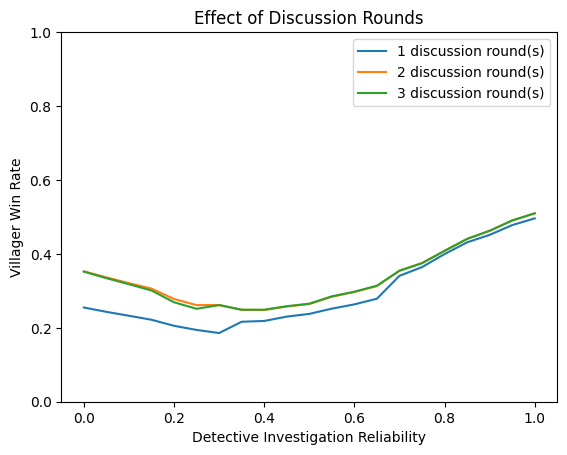

In [23]:
plt.figure()
for comparison_n_rounds, comparison_rates in round_comparison_results.items():
  plt.plot(list(comparison_rates.keys()), list(comparison_rates.values()), label=str(comparison_n_rounds) + " discussion round(s)")

plt.xlabel("Detective Investigation Reliability")
plt.ylabel("Villager Win Rate")
plt.title("Effect of Discussion Rounds")
plt.ylim(0,1)
plt.legend()
plt.show()
